# 第02章 逼近的智慧：实验与误差证据

![曲线下的面积先用4块、再用8块梯形近似](ABC共用-图片/A-章节导入.svg)

*图02-1：模板导入图，概念示意，非实测结果。保留 $y=x^2$、4与8个小区间的原问题。*

弯曲河岸旁的一块地不方便直接丈量。先用4块梯形铺一遍，再把每块切细为8块，会换来多少精度？**先预测** $\int_0^1x^2\,dx$ 的绝对误差变为原来的几分之一，再运行2.3。

本章把有限信息与函数逼近联系起来：2.1节点是否匹配并不决定区间内误差；2.2同样的多项式可以用不同基表示；2.3积分离散误差与求导误差有不同来源；2.4网络的函数值与导数应分别评价。所有量无量纲。

先修：多项式、线性代数、积分与链式法则。配套理论与证明见[正文](编写稿-正文.md)，习题见[习题](编写稿-习题.md)。

本Notebook从空内核自上而下执行。核心算法在同目录 `ch2_numerics.py`，不安装库、不下载数据；需要 NumPy、Matplotlib、IPython。自动微分由本次编写的教学模块实现，包括前向 Dual、反向 Graph 与二阶 Jet2；它们只支持本章展示的运算，不是通用训练框架。

In [1]:
from pathlib import Path
import sys, json, inspect
import numpy as np
from IPython.display import display, Image, Code
import ch2_numerics as cn

assert Path('ch2_numerics.py').is_file(), '请从本章目录打开并运行Notebook'
print('工作目录:', Path.cwd())
print(json.dumps(cn.environment(), ensure_ascii=False, indent=2))
results = {}


工作目录: /Users/yukunwang/研究生事务/研究生课程/科学计算/ch2/教材/第02章-逼近的智慧
{
  "python": "3.12.10",
  "interpreter": "/Users/yukunwang/miniforge3/envs/Scientific_Computation_2026/bin/python",
  "module_sha256": "bd652fd1ac248d5209d8cf24ea8da8785d4a0d488b0f5a578820ddf34235172e",
  "platform": "macOS-27.0.1-arm64-arm-64bit",
  "packages": {
    "numpy": "2.5.4",
    "matplotlib": "3.11.2",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0",
    "ipykernel": "7.4.0",
    "jupyter_client": "8.10.0"
  },
  "seed": 2026,
  "dtype": "float64",
  "device": "CPU",
  "extra_installs": [],
  "ad_implementation": "self-contained teaching Dual/Graph/Jet2 in ch2_numerics.py"
}


## 2.1 插值与Runge现象

**先作预测。** 对 $f(x)=1/(1+25x^2)$，把次数 $n$ 从8增加到32，等距插值误差是否必然减小？换成Chebyshev零点会怎样？

**对象与推导。** $n+1$ 个互异节点 $x_j$ 上有唯一的 $P_n$ 插值多项式。Lagrange基为 $\ell_j(x)=\prod_{k\ne j}(x-x_k)/(x_j-x_k)$。令 $w_j=1/\prod_{k\ne j}(x_j-x_k)$，重心公式为
$$p_n(x)=\frac{\sum_jw_jf(x_j)/(x-x_j)}{\sum_jw_j/(x-x_j)}\quad(x\ne x_j).$$
节点处直接返回 $f(x_j)$，避免除零。本实验用对数共同缩放计算权重；共同非零因子不改变比值。两个方案均有相同的 $n+1$ 个节点，Chebyshev零点 $x_j=\cos((2j+1)\pi/(2n+2))$ 不含端点。

**输入与独立参考。** 次数8、16、32，目标函数直接代入作为真值。6001个偏移均匀内点 $z_j=-1+2(j+0.371)/6001$ 评价误差，既不是训练误差，也不是连续区间最大误差。基准是可手算的二次多项式 $2x^2-x+3$，并用小规模直接Lagrange式核对。

**容差。** 三节点二次精确再现只含少量运算，取绝对/相对容差 $3\times10^{-15}$；Runge曲线的巨大误差不受该容差约束。此实验不外推到 $[-1,1]$ 外。

In [2]:
display(Code(inspect.getsource(cn.barycentric_weights) + '\n' + inspect.getsource(cn.barycentric_evaluate), language='python'))
results['interpolation'] = cn.interpolation_experiment()
print('n   nodes                grid maximum absolute error')
for row in results['interpolation']['rows']:
    print(f"{row['n']:2d}  {row['nodes']:20s} {row['grid_max_error']:.9g}")
print(results['interpolation']['baseline'])


def barycentric_weights(nodes):
    x = np.asarray(nodes, dtype=float)
    if x.ndim != 1 or x.size < 1 or not np.all(np.isfinite(x)):
        raise ValueError('nodes must be a finite nonempty 1-D array')
    delta = x[:, None] - x[None, :]
    np.fill_diagonal(delta, 1.)
    if np.any(delta == 0):
        raise ValueError('nodes must be distinct')
    # Common logarithmic scaling prevents products from over/underflowing.
    logw = -np.sum(np.log(np.abs(delta)), axis=1)
    return np.prod(np.sign(delta), axis=1) * np.exp(logw - logw.max())

def barycentric_evaluate(nodes, values, points):
    x, y, z = map(lambda a: np.asarray(a, dtype=float), (nodes, values, points))
    w = barycentric_weights(x)
    if y.shape != x.shape or not np.all(np.isfinite(y)) or not np.all(np.isfinite(z)):
        raise ValueError('finite values must match nodes; finite evaluation points required')
    flat = z.ravel()
    d = flat[:, None] - x[None, :]
    hit = d == 0
    safe = np.where(hit, 1., d)
    terms = w / safe
    # Node values are assigned directly, never as an inf/inf quotient.
    exact = hit.any(axis=1)
    out = np.empty(flat.size)
    out[~exact] = (terms[~exact] @ y) / terms[~exact].sum(axis=1)
    out[exact] = y[np.argmax(hit[exact], axis=1)]
    return out.reshape(z.shape)

n   nodes                grid maximum absolute error
 8  equispaced           1.04517659
 8  Chebyshev zeros      0.17083556
16  equispaced           14.3937633
16  Chebyshev zeros      0.0326135736
32  equispaced           5059.01137
32  Chebyshev zeros      0.00140174227
2x^2-x+3 at three nonnodes; direct Lagrange; 3 invalid inputs rejected


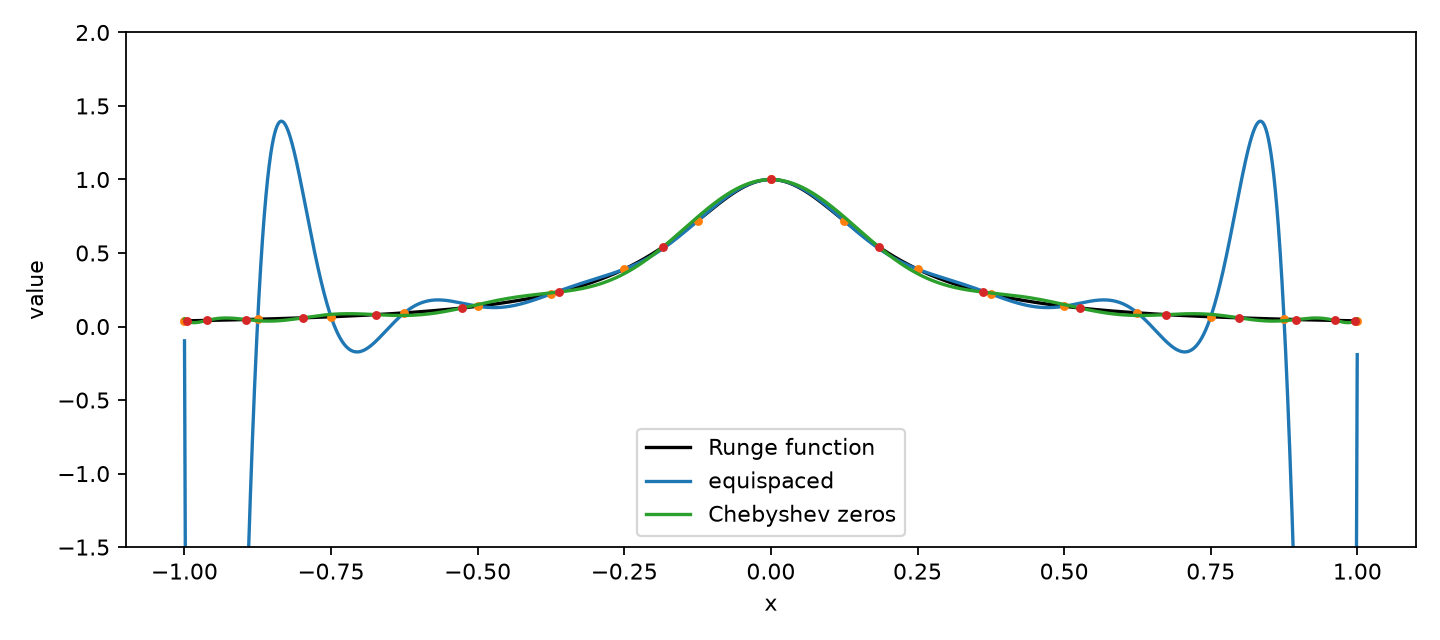

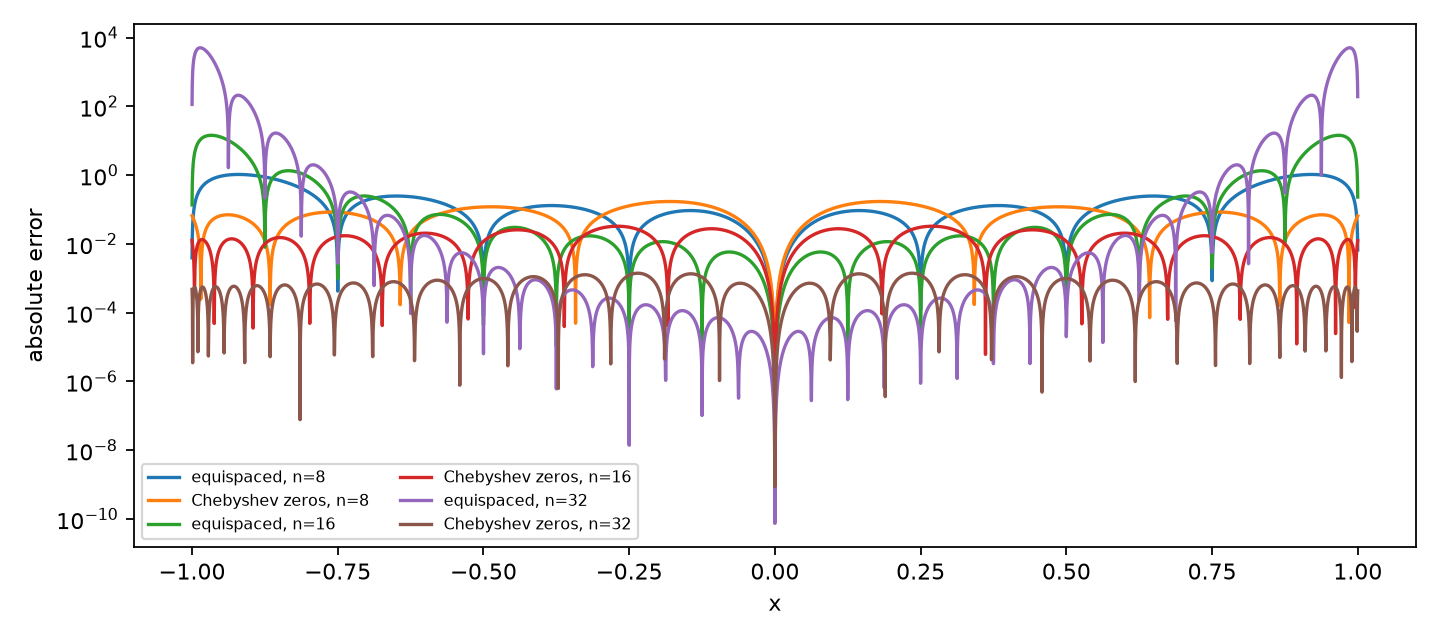

In [3]:
display(Image(filename='ABC共用-图片/experiment-runge-nodes.png'))
display(Image(filename='ABC共用-图片/experiment-runge-errors.png'))

**实际结果与解释。** 相同节点数的等距误差约为1.045、14.394、5059.011，Chebyshev零点误差约为0.17084、0.032614、0.0014017。节点值均由程序精确返回；这不代表节点之间误差小。图中的对数纵轴展示端部误差增长。`n=16` 曲线图把纵轴限制为 $[-1.5,2]$ 便于看目标，完整误差由另一张图给出。等距插值的失败不是“所有多项式都不好”，而说明节点安排与稳定表达都须考虑。

三节点二次多项式由两种实现再现；重复节点、不匹配数据与非有限节点均触发预期的 `ValueError`，没有红色中断。网格观察支持本例预测，不能替代插值余项定理或证明所有函数的收敛。

**随堂练习。** 只看节点误差为零，能否判断哪套方案更好？请用两个同次数方案的网格误差解释。

## 2.2 最小二乘与Chebyshev基

**先作预测。** 固定相同样本和次数，换一套基能否使精确最小二乘拟合变成另一个多项式？条件数会怎样？更高次数一定有更小的独立误差吗？

**定义与算法。** 用 $A_{ik}=\phi_k(x_i)$ 组成设计矩阵，求 $\min_c\|Ac-y\|_2^2$。满列秩时系数唯一。正规方程 $A^TAc=A^Ty$ 用于推导；本实验直接用 `np.linalg.lstsq`，不把正规方程当作默认数值算法。幂基为 $1,t,\ldots,t^d$，Chebyshev基由 $T_0=1,T_1=t,T_{k+1}=2tT_k-T_{k-1}$ 生成。

**输入与参考。** 41个等距样本，$y_i=e^{x_i}+\eta_i$，$\eta_i$ 由种子2026生成，标准差0.015；相同数据、相同次数12、相同未加权目标、相同列尺度（不额外归一化每列）。独立2001点使用偏移0.371的网格，以解析 $e^x$ 为真值。条件数为设计矩阵的2范数条件数，取决于基和列尺度。

**独立核查与尺度。** 三点 $(-1,-1),(0,2),(1,5)$ 的直线拟合可手算为 $2+3x$；QR只作可选的独立算法核查，不要求预先学过。给定区间 $[a,b]$ 先变换 $t=(2x-a-b)/(b-a)$，并把样本移到 $[100,102]$ 核查相同预测。重复样本导致设计矩阵秩亏时明确拒绝宣称系数唯一。

**容差。** 基间与QR预测差取 $10^{-9}$，高于本例实测舍入差，低于数据噪声0.015多个数量级；手算直线只需 $2\times10^{-15}$。尺度变换因减法舍入放宽到 $2\times10^{-12}$。

In [4]:
display(Code(inspect.getsource(cn.poly_design) + '\n' + inspect.getsource(cn.fit_polynomial), language='python'))
results['least_squares'] = cn.least_squares_experiment()
print('basis          cond_2(A)       ||Ac-y||_2    grid max error   QR difference')
for r in results['least_squares']['rows']:
    print(f"{r['basis']:12s} {r['condition_2']:13.6g} {r['residual_2']:13.6g} {r['grid_max_error']:14.6g} {r['qr_prediction_max_difference']:.3e}")
print('同数据改变次数:', results['least_squares']['degree_comparison'])


def poly_design(points, degree, basis='power', interval=(-1., 1.)):
    x = np.asarray(points, dtype=float)
    a, b = interval
    if degree < 0 or not isinstance(degree, int) or not b > a or x.ndim != 1 or not np.all(np.isfinite(x)):
        raise ValueError('finite vector, nonnegative integer degree and a<b required')
    t = (2*x-a-b)/(b-a)
    if basis == 'power':
        return np.vander(t, degree+1, increasing=True)
    if basis != 'chebyshev':
        raise ValueError('unknown basis')
    A = np.ones((len(t), degree+1))
    if degree:
        A[:, 1] = t
    for k in range(1, degree):
        A[:, k+1] = 2*t*A[:, k]-A[:, k-1]
    return A

def fit_polynomial(x, y, degree, basis='power', interval=(-1., 1.)):
    A = poly_design(x, degree, basis, interval)
    y = np.asarray(y, dtype=float)
    if y.shape != (len(x),) or not np.all(np.isfinite(y)):
        raise ValueError('finite data must match samples')
    c, _, rank, _ = np.linalg.lstsq(A, y, rcond=None)
    if rank < degree+1:
        raise ValueError('rank deficient design: coefficients are not unique')
    return c, A

basis          cond_2(A)       ||Ac-y||_2    grid max error   QR difference
power              16674.7     0.0693263      0.0189213 2.487e-14
chebyshev          2.45887     0.0693263      0.0189213 3.553e-15
同数据改变次数: [{'degree': 3, 'residual_2': 0.07773555905736426, 'grid_max_error': 0.01154065325306991}, {'degree': 12, 'residual_2': 0.06932629866490644, 'grid_max_error': 0.018921326467600252}, {'degree': 30, 'residual_2': 0.04537630439388721, 'grid_max_error': 28.217093036267748}]


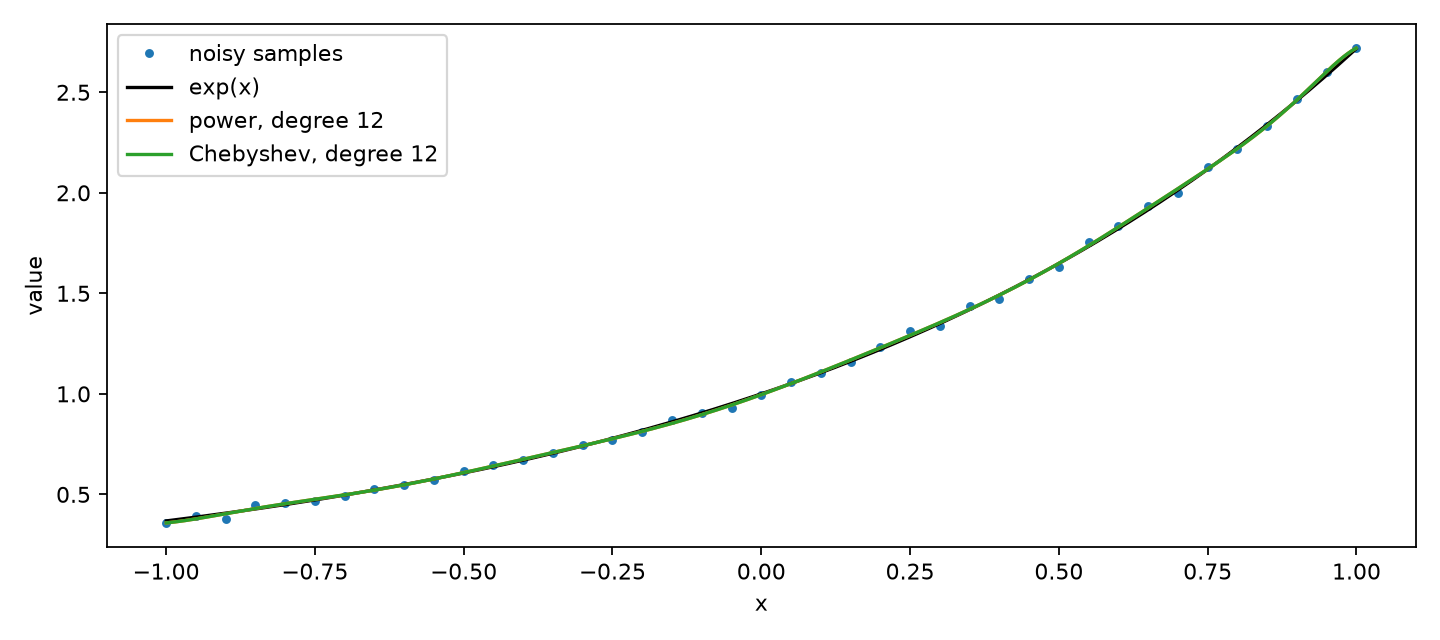

In [5]:
display(Image(filename='ABC共用-图片/experiment-least-squares.png'))

**实际结果与解释。** 幂基与Chebyshev基条件数分别约16674.7与2.45887；残差均约0.0693263，独立网格误差均约0.0189213，预测差约 $2.04\times10^{-14}$。二者张成相同 $P_{12}$，因此基变换主要改善数值表示，不能把相同拟合宣传为一种基“学得更准”。这也不是连续极小极大逼近。

同一批带噪数据中，次数3、12、30的残差依次减小至0.07774、0.06933、0.04538，独立网格误差却约为0.01154、0.01892、28.217。过高次数追逐噪声并在样本间产生振荡。单次固定噪声实验只说明这一反例，不代表已统计估计最佳次数。

**随堂练习。** 若把两套基每列乘不同常数，拟合空间是否变化？矩阵条件数是否仍可直接比较？

## 2.3 数值积分与自动微分

**先作预测。** 梯形区间数加倍后误差几分之一？中心差分的步长是否越小越好？自动微分是否需要选差分步长？

**保留导入基线。** 对 $x^2$ 在 $[0,1]$，$I=1/3$，复合梯形值 $T_N=1/3+1/(6N^2)$，故 $I-T_N=-1/(6N^2)$。以下保留模板梯形起步算法，增加4块与8块的直接对照。测试阶数来自 $\log_2(E_N/E_{2N})$，不是画一条斜线代替计算。

In [6]:
# 模板中的起步算法；仅补充排除 bool（Python中 bool 是 int 的子类）。
def trapezoid_square(n):
    if not isinstance(n, int) or isinstance(n, bool) or n < 1:
        raise ValueError("n must be a positive integer")
    x = np.linspace(0.0, 1.0, n + 1)
    y = x ** 2
    return (y[0] / 2 + y[1:-1].sum() + y[-1] / 2) / n

sizes = [4, 8, 16, 32, 64]
errors = np.array([abs(trapezoid_square(n) - 1/3) for n in sizes])
orders = np.log2(errors[:-1] / errors[1:])
np.testing.assert_allclose(errors, [1/(6*n*n) for n in sizes], rtol=1e-9)
np.testing.assert_allclose(orders, 2.0, atol=1e-8)
print({'N': sizes, 'absolute errors': errors.tolist(), 'orders': orders.tolist()})
print('E_8/E_4=', errors[1]/errors[0])


{'N': [4, 8, 16, 32, 64], 'absolute errors': [0.010416666666666685, 0.002604166666666685, 0.0006510416666666852, 0.00016276041666668517, 4.069010416668517e-05], 'orders': [1.9999999999999922, 1.9999999999999694, 1.999999999999877, 1.999999999999508]}
E_8/E_4= 0.25000000000000133


**计算图与解析基准。** 固定 $x=0.7$，$F(x)=\sin(x^2)+e^x$。置 $v_1=x^2,v_2=\sin v_1,v_3=e^x,F=v_2+v_3$。

前向链式法则给 $F'=2x\cos(x^2)+e^x$，$F''=2\cos(x^2)-4x^2\sin(x^2)+e^x$。反向从 $\bar F=1$ 开始，$\bar v_2=\bar v_3=1$，$\bar v_1=\cos v_1$，两条路径累加为 $\bar x=2x\bar v_1+e^x\bar v_3$。不能漏掉共享输入的任一路径。

Dual携带 $(v,\dot v)$，一次前向传播方向导数；Graph记录运算依赖，再对一个标量输出反向累加；Jet2携带 $(v,\dot v,\ddot v)$，其中最后一项是二阶导数，**不是**除以 $2!$ 的Taylor系数。乘法规则为 $(ab)''=a''b+2a'b'+ab''$。

**误差与容差。** 用解析表达式独立核查三种AD的一阶导数和Jet2二阶导数，取 $2$–$3\times10^{-15}$ 的绝对/相对容差，适合本例只有数次运算且量级约1的情况。AD不含差分截断误差，仍受浮点与基本函数实现误差影响。差分在 $10^{-1}$ 至 $10^{-16}$ 的61个对数步长上全部运行。

In [7]:
display(Code(inspect.getsource(cn.Dual) + '\n' + inspect.getsource(cn.Jet2), language='python'))
# 反向图本节只有标量。2.4扩展为批量值、标量loss；完整Graph类在模块内。
display(Code(inspect.getsource(cn.Graph.backward), language='python'))
results['differentiation'] = cn.differentiation_experiment()
r = results['differentiation']
print({k:r[k] for k in ('x','F','analytic_d1','analytic_d2','dual_d1','reverse_d1','jet_d2','manual_reverse')})
print('最佳中心差分:', {k:r['difference'][k] for k in ('best_central_h','best_central_error')})


class Dual:
    """First order forward AD: value and directional derivative."""
    def __init__(self, value, d=0.): self.value, self.d = np.asarray(value), np.asarray(d)
    @staticmethod
    def lift(x): return x if isinstance(x, Dual) else Dual(x)
    def __add__(self, other):
        b=self.lift(other); return Dual(self.value+b.value, self.d+b.d)
    __radd__=__add__
    def __mul__(self, other):
        b=self.lift(other); return Dual(self.value*b.value, self.d*b.value+self.value*b.d)
    __rmul__=__mul__
    def sin(self): return Dual(np.sin(self.value), np.cos(self.value)*self.d)
    def exp(self):
        e=np.exp(self.value); return Dual(e,e*self.d)
    def tanh(self):
        t=np.tanh(self.value); return Dual(t,(1-t*t)*self.d)

class Jet2:
    """Second order forward AD; d2 is the derivative, not Taylor coefficient."""
    def __init__(self, value, d=0., d2=0.):
        self.value,self.d,self.d2=map(np.asarray,(value,d,d2))
    @staticmethod
    def lift(x): return x if isinstance(x,Jet2) else Jet2(x)
    def __add__(self,other):
        b=self.lift(other);return Jet2(self.value+b.value,self.d+b.d,self.d2+b.d2)
    __radd__=__add__
    def __mul__(self,other):
        b=self.lift(other)
        return Jet2(self.value*b.value,self.d*b.value+self.value*b.d,
                    self.d2*b.value+2*self.d*b.d+self.value*b.d2)
    __rmul__=__mul__
    def sin(self):
        v=self.value;return Jet2(np.sin(v),np.cos(v)*self.d,np.cos(v)*self.d2-np.sin(v)*self.d**2)
    def exp(self):
        e=np.exp(self.value);return Jet2(e,e*self.d,e*(self.d2+self.d**2))
    def tanh(self):
        t=np.tanh(self.value);s=1-t*t
        return Jet2(t,s*self.d,s*self.d2-2*t*s*self.d**2)

def backward(self):
        if self.value.ndim!=0: raise ValueError('backward requires scalar output')
        order=[];seen=set()
        def visit(node):
            if id(node) not in seen:
                seen.add(id(node))
                for parent,_ in node.parents: visit(parent)
                order.append(node)
        visit(self)
        for node in order:node.grad=np.zeros_like(node.value)
        self.grad=np.ones_like(self.value)
        for node in reversed(order):
            for parent,pull in node.parents:parent.grad+=pull(node.grad)

{'x': 0.7, 'F': np.float64(2.4843785956416347), 'analytic_d1': np.float64(3.2490187095246466), 'analytic_d2': np.float64(2.85599168387525), 'dual_d1': 3.2490187095246466, 'reverse_d1': 3.249018709524647, 'jet_d2': 2.85599168387525, 'manual_reverse': {'bar_exp': 1.0, 'bar_sin': 1.0, 'bar_square': 0.8823328586101216, 'bar_x': 3.2490187095246466}}
最佳中心差分: {'best_central_h': 5.623413251903491e-06, 'best_central_error': 4.225197969276451e-11}


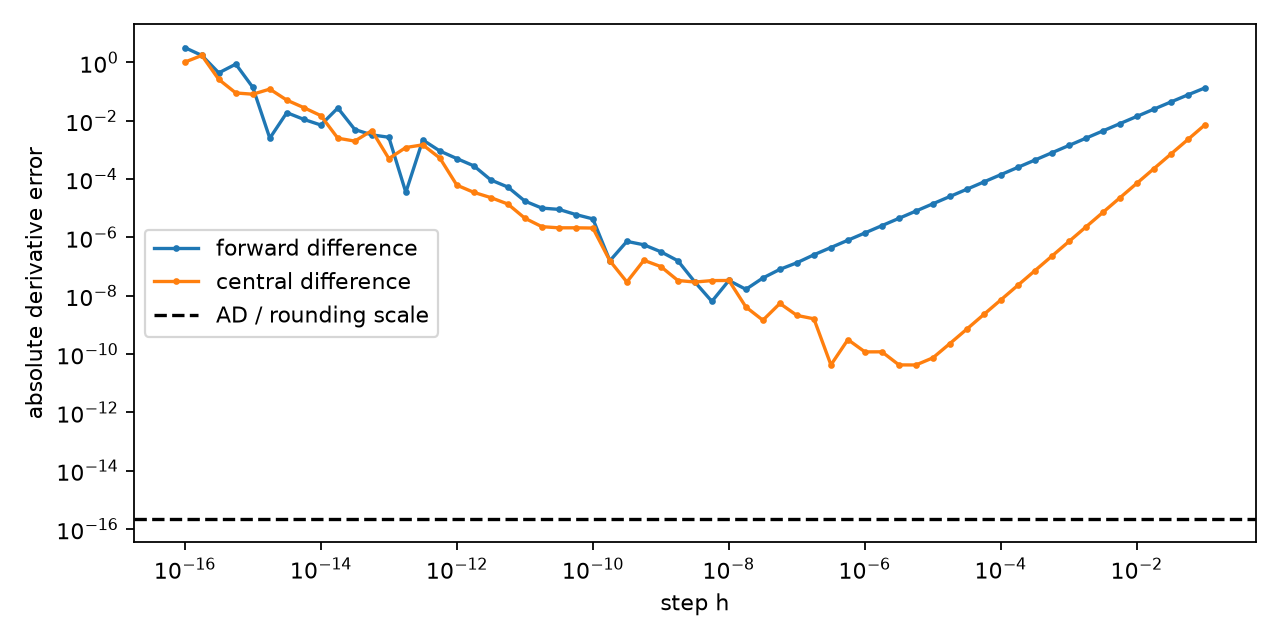

In [8]:
display(Image(filename='ABC共用-图片/experiment-difference-steps.png'))

**实际结果与解释。** $T_4=0.34375,T_8=0.3359375$，误差分别约0.0104167与0.00260417，误差比为1/4；后续实测阶均约2。梯形公式高估凸函数面积。

$F(0.7)\approx2.48437859564$，解析 $F'\approx3.24901870952$，$F''\approx2.85599168388$。Dual与Jet2在本机一阶/二阶结果与上述浮点解析表达式相同，反向一阶差约 $4.44\times10^{-16}$，不能由此称AD“无误差”。差分误差图出现先降后升，小步长的相减抵消使“步长越小越好”的预测失败。图中AD线按机器精度下限画出，避免零误差在对数轴上不可见，并非证明一般误差上界。

**随堂练习。** 用 $x^2$ 的手算积分和 $F$ 的链式法则解释，为何“积分误差为零/很小”不能说明“导数算法正确”。

## 2.4 光滑小网络：值、输入导数与参数梯度

**先作预测。** 只用函数值训练，是否会让一、二阶输入导数同样准确？自动微分给出的导数计算准确，是否意味着它接近目标导数？

**网络定义。** 一个输入、一个输出、12个隐藏单元，
$$u_\theta(x)=c+\sum_{j=1}^{12}a_j\tanh(w_jx+b_j),\qquad\theta=(a,w,b,c)\in\mathbb R^{37}.$$
隐藏单元是“仿射变换 $w_jx+b_j$ 后接激活函数 $\tanh$”，输出为它们的加权和。训练是改变37个实数参数，以减小81个等距点上的平均平方误差；输入导数是固定参数后对 $x$ 求导，二者任务不同。

**真实训练设置。** 目标 $\sin(\pi x)$，区间 $[-1,1]$；种子2026，CPU、float64。全体37参数均训练，值损失 $L=81^{-1}\sum_i(u_\theta(x_i)-\sin(\pi x_i))^2$，没有导数损失。Adam迭代14000次，$\beta_1=0.9,\beta_2=0.999,\epsilon=10^{-8}$；前8000步学习率0.01，其后0.002。学习率在评价前固定。Adam维护梯度的一阶与二阶滑动平均，作偏差修正后更新参数，代码给出全部步骤。

反向Graph支持逐元素批量数组和求和，广播的反向必须沿扩展维度求和；最终输出始终是标量loss。每步重新建立图并清零/累加梯度。以下展示训练循环，完整规则在模块中可检查。

In [9]:
display(Code(inspect.getsource(cn.train_network), language='python'))
results['network'] = cn.network_experiment()
r = results['network']
print(json.dumps({k:r[k] for k in ('seed','width','parameter_count','training_points','test_points','steps','optimizer','training_scope','final_loss','train_grid_max_error','independent_grid_max_errors','training_seconds')}, ensure_ascii=False, indent=2))


def train_network(steps=14000,width=12):
    rng=np.random.default_rng(SEED)
    x=np.linspace(-1.,1.,81);y=np.sin(np.pi*x)
    params=[rng.normal(0.,.3,width),rng.normal(0.,1.,width),rng.normal(0.,.4,width),np.array(0.)]
    m=[np.zeros_like(p) for p in params];v=[np.zeros_like(p) for p in params]
    history=[];start=time.perf_counter()
    for step in range(1,steps+1):
        loss,grads=network_loss(params,x,y)
        # Deliberate two-stage learning-rate schedule, fixed before evaluation.
        rate=.01 if step<=8000 else .002
        for j,g in enumerate(grads):
            m[j]=.9*m[j]+.1*g;v[j]=.999*v[j]+.001*g*g
            params[j]-=rate*(m[j]/(1-.9**step))/(np.sqrt(v[j]/(1-.999**step))+1e-8)
        if step==1 or step%200==0:history.append([step,loss])
    final,_=network_loss(params,x,y)
    return params,x,y,history,final,time.perf_counter()-start

{
  "seed": 2026,
  "width": 12,
  "parameter_count": 37,
  "training_points": 81,
  "test_points": 2001,
  "steps": 14000,
  "optimizer": "Adam beta1=.9 beta2=.999 eps=1e-8; learning rate .01 for 8000 steps then .002",
  "training_scope": "all a,w,b,c jointly; value-only loss",
  "final_loss": 1.0958828192730512e-06,
  "train_grid_max_error": 0.0030549597961374462,
  "independent_grid_max_errors": {
    "value": 0.003011439088143302,
    "first_derivative": 0.11705968837788028,
    "second_derivative": 1.6468800288529928
  },
  "training_seconds": 1.1181662919989321
}


**独立核查。** 测试网格 $z_j=-1+2(j+0.371)/2001$ 与全部训练点均不重合；程序断言最小距离超过 $10^{-12}$。测试真值是一并独立写出的 $\sin(\pi x),\pi\cos(\pi x),-\pi^2\sin(\pi x)$。网格最大绝对误差是有限采样统计量，不是已求出的连续一致范数。

令 $t_j=\tanh(w_jx+b_j),s_j=1-t_j^2$。独立解析网络公式为
$$u_\theta'=\sum_ja_jw_js_j,\qquad u_\theta''=-2\sum_ja_jw_j^2t_js_j.$$
它与Jet2逐层求导互相比对，容差 $3\times10^{-13}$ 覆盖约12项累加舍入；**核查的是真实网络导数计算，不是与目标导数的误差**。

参数梯度再由独立公式 $\partial_{a_j}L=2\operatorname{mean}(rt_j)$、$\partial_{w_j}L=2\operatorname{mean}(ra_js_jx)$、$\partial_{b_j}L=2\operatorname{mean}(ra_js_j)$、$\partial_cL=2\operatorname{mean}(r)$ 核查。绝对容差 $3\times10^{-14}$ 防止近零梯度的相对误差误导；另取单位参数方向与中心差分比较，步长 $10^{-5}$，绝对容差 $10^{-8}$，允许其差分截断和抵消。没有用另一个AD实现充当唯一真值。

Jet2 vs analytic network [value,d1,d2]: [1.1102230246251565e-15, 1.7763568394002505e-15, 3.552713678800501e-15]
reverse vs analytic parameter gradients [a,w,b,c]: [1.6263032587282567e-19, 6.776263578034403e-20, 1.0842021724855044e-19, 0.0]
parameter directional check: {'reverse': 0.00020467502509689963, 'central_difference': 0.0002046750190381995, 'h': 1e-05, 'absolute_difference': 6.058700118211427e-12}


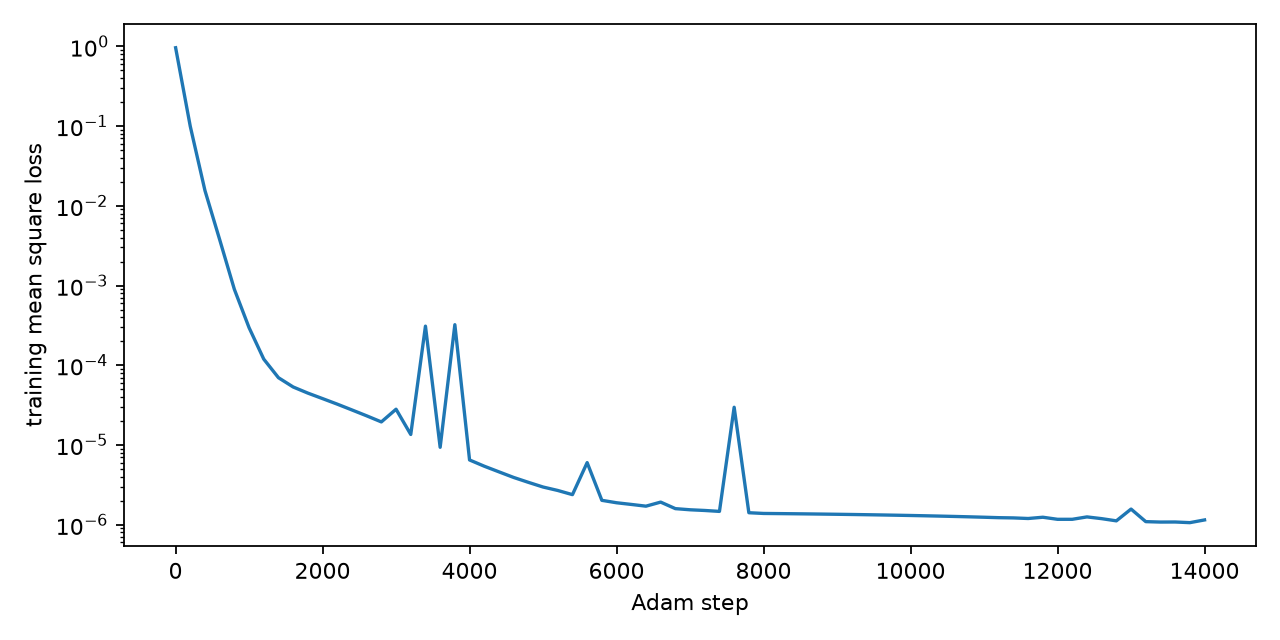

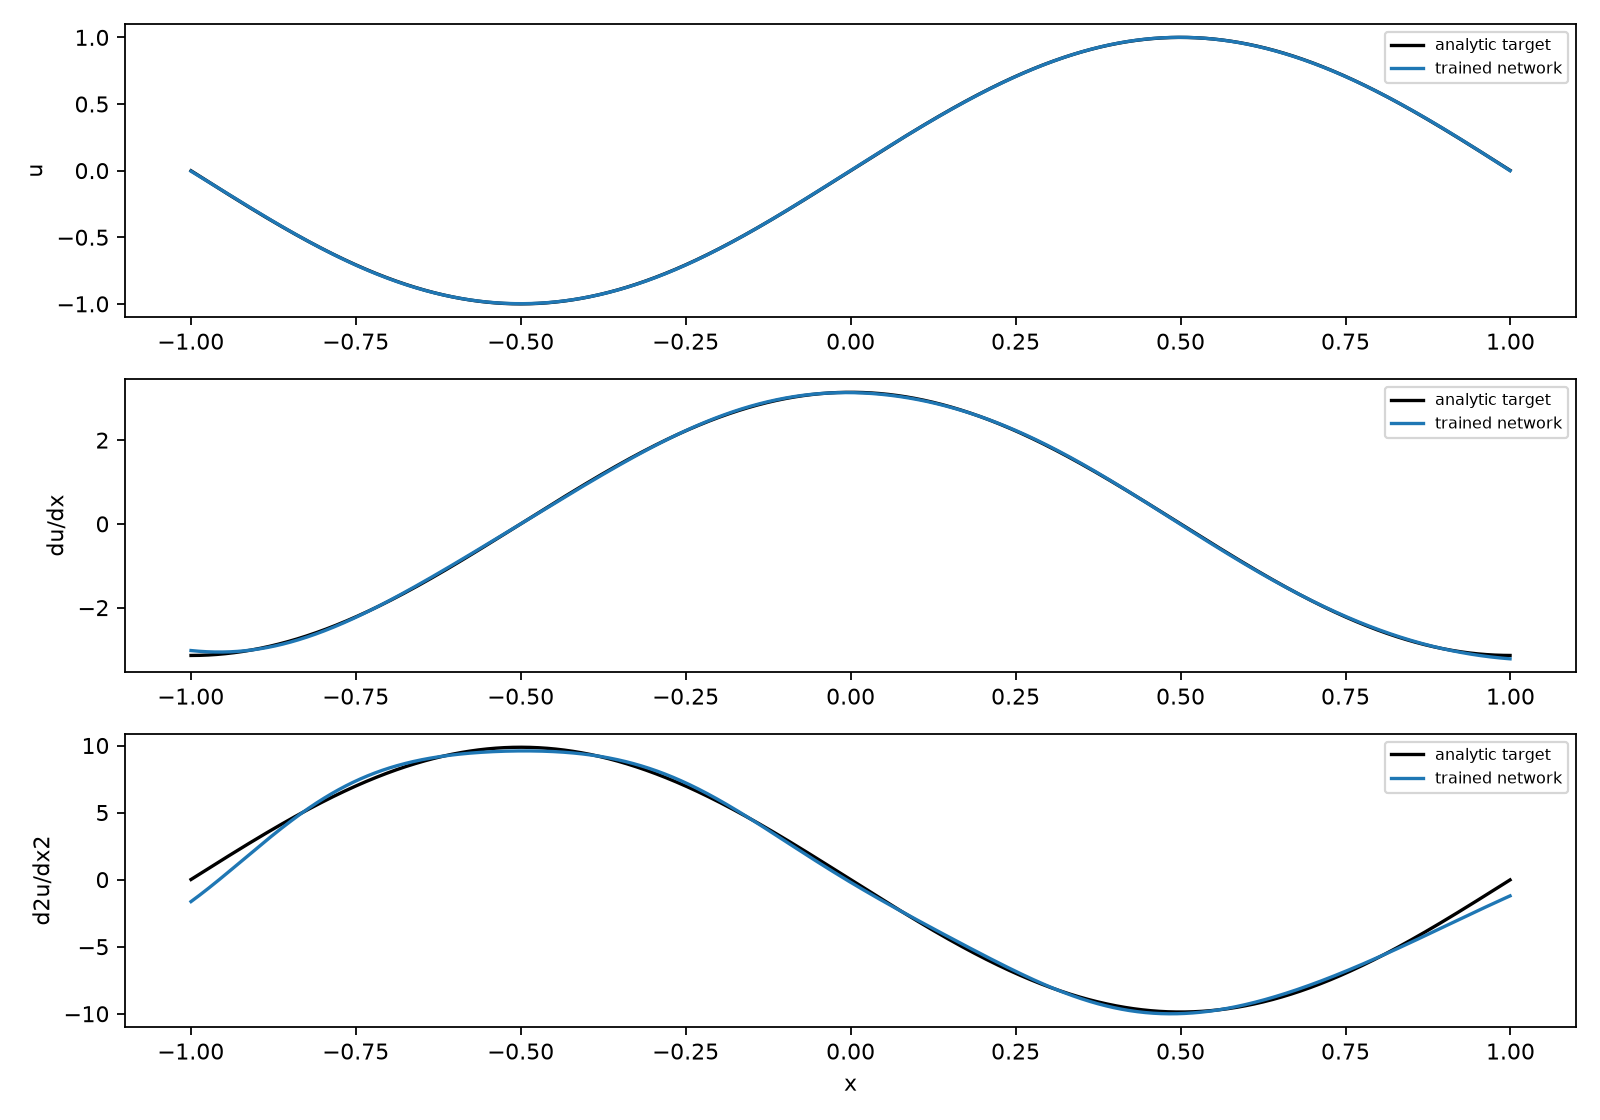

In [10]:
r = results['network']
print('Jet2 vs analytic network [value,d1,d2]:', r['jet_vs_analytic_max_differences'])
print('reverse vs analytic parameter gradients [a,w,b,c]:', r['reverse_vs_analytic_parameter_gradient_max_differences'])
print('parameter directional check:', r['directional_gradient'])
display(Image(filename='ABC共用-图片/experiment-network-loss.png'))
display(Image(filename='ABC共用-图片/experiment-network-derivatives.png'))


**实际结果与局限。** 训练后值损失约 $1.09588\times10^{-6}$，训练点最大误差约0.003055；独立网格上值、一阶导、二阶导的最大绝对误差约0.003011、0.117060、1.64688。它是一次固定种子的小规模真实训练，未作多种子统计或超参数最优性研究。损失曲线可有震荡；仅降低值损失不保证导数误差同步降低。程序每200步保存一次更新前的loss，最终loss另在最后更新后重新计算。

Jet2与网络解析式最大差不超过 $3.56\times10^{-15}$，反向参数梯度与解析式差约 $10^{-19}$，方向差分差约 $6.06\times10^{-12}$。导数算得准确与导数逼近得准确必须区分。训练耗时以本次输出为准，机器、BLAS和平台可能使末位与耗时变化。

**两个可核查的反例。**

1. $\operatorname{ReLU}(x)=\max(0,x)$ 在零点不可微，其他点二阶导为零。在零点用中心二阶差分得到 $1/h$，步长越小越大，不能当作经典二阶导数；在远离零的同一线性段上二阶差分为零。因而强形式二阶微分方程需要额外关注激活光滑性。
2. $u(x)=f(x)+10^{-4}\sin(100x)$ 的函数误差连续上确界为 $10^{-4}$，一阶为0.01，二阶为1。这些值可由解析三角函数和区间内极值点直接证明，表明小振幅高频扰动会放大导数误差。它不是另一次训练结果。

PINN会用输入导数构造方程残差，再对参数求梯度。本实验只准备这两种求导，不进行PDE训练或声称已求解方程。

{
  "high_frequency": {
    "k": 100,
    "epsilon": 0.0001,
    "continuous_sup_errors": [
      0.0001,
      0.01,
      1.0
    ]
  },
  "relu": {
    "formula": "max(0,x): derivative 0 for x<0 and 1 for x>0; not differentiable at 0",
    "second_difference_away": [
      0.0,
      0.0
    ],
    "kink_second_difference": [
      9.999999999999998,
      100.0,
      1000.0000000000001
    ],
    "kink_steps": [
      0.1,
      0.01,
      0.001
    ]
  }
}


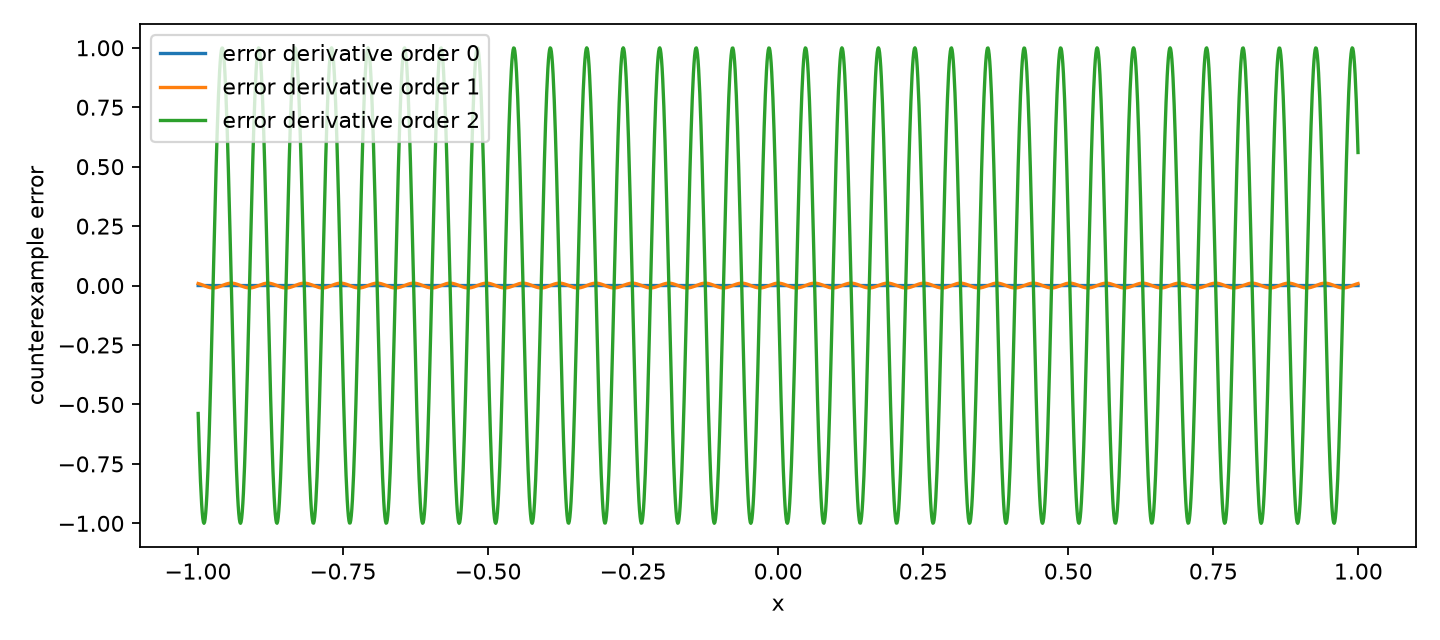

In [11]:
print(json.dumps(results['network']['counterexamples'], ensure_ascii=False, indent=2))
display(Image(filename='ABC共用-图片/experiment-high-frequency.png'))

## 回到开场：用证据回答

对明确给定的 $x^2$，4块变8块梯形的误差变成原来的四分之一，来自精确公式 $1/(6N^2)$，也由本Notebook的数值核查支持；河岸比喻不代表任意不光滑曲线都有同样收敛阶。

有限信息的可靠性由对象、节点/样本、表示、运算与评价量共同决定。插值匹配节点；最小二乘减少给定离散残差；自动微分计算给定程序的导数。它们各自的准确性都不能自动转化为区间内函数、独立数据或高阶导数的准确性。

**练习。** (1) 用实际结果设计一次“增加节点却更差”的判断题；(2) 解释同空间换基和改变次数的区别；(3) 手写 $F$ 的反向累加；(4) 给出值误差趋零但二阶导误差不趋零的函数列。参考答案在本章配套文件。

## 保存、来源与复现范围

导入图与 $x^2$ 梯形起步算法来自课程模板，本次保留其数学内容并增加4/8对照、独立参考与错误输入处理。其余代码及实验图为本章本次编写和实际运行产生，理论文献及原文定位统一见正文参考表与来源核查记录；没有将文献里的曲线伪称为本次结果。

最后一个单元把本次输出写入JSON并记录模块SHA256、解释器和库版本。Notebook依赖同目录模块及图片目录，从空内核顺序执行保存。可用仓库根目录工具 `tools/execute_notebook.py` 重新执行；须用课程指定Python调用该工具。所有断言在本次执行通过，只验证列出的案例与边界，不构成一般数学定理的证明。

In [12]:
Path('实验结果.json').write_text(json.dumps(results, ensure_ascii=False, indent=2)+'\n', encoding='utf-8')
Path('环境版本.json').write_text(json.dumps(cn.environment(), ensure_ascii=False, indent=2)+'\n', encoding='utf-8')
print('全部实验完成；所有本Notebook调用的断言通过。')
print('结果:', Path('实验结果.json').resolve())
print('环境:', Path('环境版本.json').resolve())


全部实验完成；所有本Notebook调用的断言通过。
结果: /Users/yukunwang/研究生事务/研究生课程/科学计算/ch2/教材/第02章-逼近的智慧/实验结果.json
环境: /Users/yukunwang/研究生事务/研究生课程/科学计算/ch2/教材/第02章-逼近的智慧/环境版本.json
